# Sector and Subsector Means and Medians of the Main Relevance Score Relative to the Sample

| Item | Description |
|---|---|
| Goal | Four figures for the main relevance measure, the cosine similarity between a firm-level summary of 10-K Item 1s and the policy summary of legislator statements on consumer data privacy legislation: one horizontal bar per NAICS two-digit sector and, separately, per NAICS three-digit subsector, showing the group mean of the firm score minus the sample mean (two figures) and the group median minus the sample median (two figures), so that zero is the sample statistic, groups sorted from the highest to the lowest, with nested 90, 95, and 99 percent intervals. The two-digit mean figure is the one-measure version of Figure 9 of the archived T3.9.3. |
| Input | `output/T3.8.3/firm_relevance_scores_wide.csv` (T3.8.3); the CRSP-Compustat link file `crsp_compustat_link.dta` in the source data folder for each firm's Compustat NAICS code. |
| Output | `output/T3.9.3/naics2_sector_means_and_medians.csv` and `output/T3.9.3/naics3_subsector_means_and_medians.csv`: one row per group with the number of firms, the mean and the median, their differences from the sample mean and median, and the bounds of the three intervals of each, bounds relative to the sample statistic. `output/T3.9.3/fig_<sector\|subsector>_<mean\|median>_minus_sample_<mean\|median>_policy_summary_firm_summary_cosine_<naics2\|naics3>.{png,svg,pdf}`, four figures. |
| Unit | A NAICS group; the firm is the unit the group statistic is taken over. Firms are those of the sample set by `SAMPLE`: all years (every fiscal year a firm filed, 1999 to 2025; 1,058 firms) or the three years (fiscal 2010, 2015, 2020; 841 firms). |
| Groups | Compustat's NAICS code for the firm. Two digits give the sector, with 31 to 33 merged into manufacturing, 44 to 45 into retail trade, and 48 to 49 into transportation and warehousing, as in T3.9.1 and T3.9.2. Three digits give the subsector, named by NAICS 2022 where the code exists in that vintage and by the older vintage otherwise, as in T3.9.4. Groups with fewer than `MIN_FIRMS` firms at their level are left out of the figures and named in the Notes. |
| Measure | `MEASURE_ID`, T3.8.3's `summaries \| policy_summary \| firm_summary`, as in T3.9.1 and T3.9.2. |
| Intervals | For the mean, two-sided normal confidence intervals from the standard deviation of the firm scores within the group (1.645, 1.960, and 2.576 standard errors). For the median, percentile bootstrap intervals: the group's firms are resampled with replacement `N_BOOTSTRAP` times (seed `BOOTSTRAP_SEED`), the median is taken each time, and the intervals are the central 90, 95, and 99 percent of those medians, which can be asymmetric. All are nested and drawn without caps, the thickest line for 90 percent and the thinnest for 99 percent. |
| Wording | Every title, axis title, and tick label spells out what is measured, as in T3.9.1 and T3.9.2: each tick label carries the group name, its NAICS codes, and its number of firms. Axis titles and tick labels are in title case at the user's request; the figure titles follow S3 title case. |
| Style | S3: 9 by 6 inches, Times, 0.5 cm margins, no text inside the plot, GREY bars with BLUE intervals so that the intervals stand out, a solid BLACK zero line, no legend (one series; the intervals are explained in the Notes), title and notes in Markdown below. The three-digit figures have about thirty rows, so their tick labels are one line in a smaller size. |

See `README.md` in the TEMP folder for the surrounding steps, `T3.8.3` for the measure, the archived `T3.9.3 - Figure - Most and Least Relevant Industries` (in `archive`) for the two-digit mean figure on every measure, and `T3.9.1`, `T3.9.2`, and `T3.9.4` for the distribution and the firms on this measure.


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


## Step 2. Define file locations, the measure, the group names, the statistics, and the wording

The wording is built from the same two phrases as T3.9.1 and T3.9.2. The subsector names are NAICS 2022 names, shortened where a name is long; codes that exist only in older NAICS vintages are named by that vintage.


In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
SOURCE_DATA_FOLDER = Path("/project2/mmiric_1435/acroh/llm_method/data")
NOTEBOOK_SUBFOLDER = Path("T3 - Topic Relevance and Corporate Disclosure/TEMP")
NOTEBOOK_NAME = "T3.9.3"  # the identifier names this notebook's output folder
TEMP_OUTPUT = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output"
OUTPUT_FOLDER = TEMP_OUTPUT / NOTEBOOK_NAME
SCORES_FILE = TEMP_OUTPUT / "T3.8.3/firm_relevance_scores_wide.csv"
LINK_FILE = SOURCE_DATA_FOLDER / "interim/repo_data/raw/01_firm_id/crsp_compustat_link.dta"

SAMPLE = "all_years"  # the main sample; "three_years" for the three-year figures
SAMPLE_WORDS = {"three_years": "the three-year sample (fiscal years 2010, 2015, and 2020)", "all_years": "the all-years sample (every fiscal year a firm filed, 1999 to 2025)"}
MEASURE_ID = "summaries | policy_summary | firm_summary"
CONFIDENCE_LEVELS = [90, 95, 99]  # nested intervals; the wider the interval, the thinner its line
Z_VALUES = {90: 1.645, 95: 1.960, 99: 2.576}  # two-sided normal critical values for the mean
N_BOOTSTRAP = 5000  # resamples of each group's firms for the median's intervals
BOOTSTRAP_SEED = 0
NAICS_SECTORS = {  # two-digit code -> sector name; codes that share a sector map to the same name
    "11": "Agriculture, forestry, fishing and hunting", "21": "Mining, quarrying, and oil and gas extraction", "22": "Utilities", "23": "Construction",
    "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing", "42": "Wholesale trade", "44": "Retail trade", "45": "Retail trade",
    "48": "Transportation and warehousing", "49": "Transportation and warehousing", "51": "Information", "52": "Finance and insurance",
    "53": "Real estate and rental and leasing", "54": "Professional, scientific, and technical services", "55": "Management of companies and enterprises",
    "56": "Administrative and support and waste management", "61": "Educational services", "62": "Health care and social assistance",
    "71": "Arts, entertainment, and recreation", "72": "Accommodation and food services", "81": "Other services", "92": "Public administration",
    "99": "Unclassified",
}
NAICS_SUBSECTORS = {  # three-digit code -> subsector name (NAICS 2022, shortened; older vintages marked); "42" is the one firm with a two-digit code only
    "111": "Crop Production", "113": "Forestry and Logging", "211": "Oil and Gas Extraction", "212": "Mining, except Oil and Gas", "213": "Support Activities for Mining",
    "221": "Utilities", "236": "Construction of Buildings", "237": "Heavy and Civil Engineering Construction", "238": "Specialty Trade Contractors",
    "311": "Food Manufacturing", "312": "Beverage and Tobacco Product Manufacturing", "313": "Textile Mills", "314": "Textile Product Mills", "315": "Apparel Manufacturing",
    "316": "Leather and Allied Product Manufacturing", "321": "Wood Product Manufacturing", "322": "Paper Manufacturing", "323": "Printing and Related Support Activities",
    "324": "Petroleum and Coal Products Manufacturing", "325": "Chemical Manufacturing", "326": "Plastics and Rubber Products Manufacturing",
    "327": "Nonmetallic Mineral Product Manufacturing", "331": "Primary Metal Manufacturing", "332": "Fabricated Metal Product Manufacturing", "333": "Machinery Manufacturing",
    "334": "Computer and Electronic Product Manufacturing", "335": "Electrical Equipment and Appliance Manufacturing", "336": "Transportation Equipment Manufacturing",
    "337": "Furniture and Related Product Manufacturing", "339": "Miscellaneous Manufacturing",
    "42": "Wholesale Trade, No Three-Digit Code", "422": "Wholesale Trade, Nondurable Goods (NAICS 1997)", "423": "Merchant Wholesalers, Durable Goods",
    "424": "Merchant Wholesalers, Nondurable Goods", "425": "Wholesale Trade Agents and Brokers",
    "441": "Motor Vehicle and Parts Dealers", "443": "Electronics and Appliance Stores (NAICS 2017)", "444": "Building Material and Garden Supplies Dealers",
    "445": "Food and Beverage Retailers", "446": "Health and Personal Care Stores (NAICS 2017)", "448": "Clothing and Clothing Accessories Stores (NAICS 2017)",
    "449": "Furniture, Electronics, and Appliance Retailers", "451": "Sporting Goods, Hobby, and Book Stores (NAICS 2017)",
    "452": "General Merchandise Stores (NAICS 2017)", "453": "Miscellaneous Store Retailers (NAICS 2017)", "455": "General Merchandise Retailers",
    "456": "Health and Personal Care Retailers", "458": "Clothing, Shoe, and Jewelry Retailers", "459": "Sporting Goods, Hobby, Book, and Miscellaneous Retailers",
    "481": "Air Transportation", "482": "Rail Transportation", "483": "Water Transportation", "484": "Truck Transportation", "485": "Transit and Ground Passenger Transportation",
    "486": "Pipeline Transportation", "488": "Support Activities for Transportation", "492": "Couriers and Messengers",
    "511": "Publishing Industries, except Internet (NAICS 2017)", "512": "Motion Picture and Sound Recording Industries", "513": "Publishing Industries",
    "515": "Broadcasting, except Internet (NAICS 2017)", "516": "Broadcasting and Content Providers", "517": "Telecommunications",
    "518": "Computing Infrastructure and Data Processing", "519": "Web Search Portals and Other Information Services",
    "522": "Credit Intermediation and Related Activities", "523": "Securities and Other Financial Investments", "524": "Insurance Carriers and Related Activities",
    "525": "Funds, Trusts, and Other Financial Vehicles", "531": "Real Estate", "532": "Rental and Leasing Services", "533": "Lessors of Nonfinancial Intangible Assets",
    "541": "Professional, Scientific, and Technical Services", "561": "Administrative and Support Services", "562": "Waste Management and Remediation Services",
    "611": "Educational Services", "621": "Ambulatory Health Care Services", "622": "Hospitals", "623": "Nursing and Residential Care Facilities",
    "711": "Performing Arts, Spectator Sports, and Related Industries", "713": "Amusement, Gambling, and Recreation Industries", "721": "Accommodation",
    "722": "Food Services and Drinking Places", "812": "Personal and Laundry Services", "999": "Unclassified",
}
LOWERCASE_WORDS = {"a", "an", "the", "and", "or", "but", "of", "in", "on", "at", "to", "for", "by", "except"}  # kept lowercase in title case
SECTOR_TITLES = {name: " ".join(word if word in LOWERCASE_WORDS and i > 0 else word[0].upper() + word[1:] for i, word in enumerate(name.split(" ")))
                 for name in set(NAICS_SECTORS.values())}
SECTOR_CODES = {}  # sector name -> "51" or "31 to 33"
for code, name in NAICS_SECTORS.items():
    codes = sorted(c for c, n in NAICS_SECTORS.items() if n == name)
    SECTOR_CODES[name] = codes[0] if len(codes) == 1 else f"{codes[0]} to {codes[-1]}"
LEVELS = {  # level -> settings
    "naics2": {"column": "sector", "code_column": "naics2", "min_firms": 5, "group": "Sector", "level_title": "NAICS Two-Digit Sector", "level_words": "two-digit sector",
               "y_title": "NAICS Two-Digit Sector (NAICS Codes, Number of Firms)", "tick_lines": 2, "tick_size": 9},
    "naics3": {"column": "subsector", "code_column": "naics3", "min_firms": 10, "group": "Subsector", "level_title": "NAICS Three-Digit Subsector", "level_words": "three-digit subsector",
               "y_title": "NAICS Three-Digit Subsector (NAICS Code, Number of Firms)", "tick_lines": 1, "tick_size": 7.5},
}
STATISTICS = {"mean": "Mean", "median": "Median"}

# Wording. The two texts compared, in title case, then the titles built from them.
FIRM_SUMMARY_TITLE = "a Firm-Level Summary of 10-K Item 1s"
POLICY_SUMMARY_TITLE = "the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation"
SCORE_TITLE = f"Cosine Similarity Between {FIRM_SUMMARY_TITLE} and {POLICY_SUMMARY_TITLE}"
SCORE_WORDS = ("the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's "
               "yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the "
               "language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. "
               "A higher score means that the firm's business description is closer to the policy summary")
SOURCE = "10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Outputs: {OUTPUT_FOLDER}")


Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.3


## Step 3. Figure style

The S3 settings: canvas, font, colors, horizontal background lines only. GREY bars, BLUE intervals, a BLACK zero line; the tick label size is set per level.


In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
ZERO_LINE_WIDTH = 0.8 / 3  # S3 zero line
BAR_HEIGHT = 0.7
INTERVAL_WIDTHS = {90: 3.2, 95: 1.8, 99: 0.8}  # line widths of the nested intervals, thickest for the narrowest
EXPORT_DPI = 300

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK


## Step 4. Load the scores and attach the NAICS sector and subsector to every firm

The wide table of T3.8.3, the chosen sample only; the codes come from the link file exactly as in T3.9.1 and T3.9.2. The measure column must be present and complete, and every code must have a sector and a subsector name.


In [4]:
wide = pd.read_csv(SCORES_FILE, dtype={"gvkey": str})
wide = wide.loc[wide["sample"].eq(SAMPLE)].reset_index(drop=True)
assert MEASURE_ID in wide.columns, MEASURE_ID
assert wide[MEASURE_ID].notna().all(), f"{int(wide[MEASURE_ID].isna().sum())} firms without a score"

link = pd.read_stata(LINK_FILE, columns=["GVKEY", "naics"])
link["gvkey"] = link["GVKEY"].astype(str).str.zfill(6)
link["naics"] = link["naics"].astype(str).str.strip().replace({"": None, "nan": None})
link = link.dropna(subset=["naics"])
assert link.groupby("gvkey")["naics"].nunique().le(1).all(), "a gvkey with two NAICS codes"
naics = link.drop_duplicates("gvkey").set_index("gvkey")["naics"]
wide["naics"] = wide["gvkey"].map(naics)
assert wide["naics"].notna().all(), f"{int(wide['naics'].isna().sum())} firms without a NAICS code"
wide["naics2"] = wide["naics"].str[:2]
assert wide["naics2"].isin(NAICS_SECTORS).all(), sorted(set(wide["naics2"]) - set(NAICS_SECTORS))
wide["sector"] = wide["naics2"].map(NAICS_SECTORS)
wide["naics3"] = wide["naics"].str[:3]
assert wide["naics3"].isin(NAICS_SUBSECTORS).all(), sorted(set(wide["naics3"]) - set(NAICS_SUBSECTORS))
wide["subsector"] = wide["naics3"].map(NAICS_SUBSECTORS)
print(f"Firms in the {SAMPLE} sample: {len(wide):,}; two-digit sectors: {wide['sector'].nunique()}; three-digit subsectors: {wide['naics3'].nunique()}")


Firms in the all_years sample: 1,058; two-digit sectors: 19; three-digit subsectors: 85


## Step 5. Compute the group means and medians, the sample mean and median, and the intervals

For each level and group: the number of firms; the mean, its standard deviation and standard error, and the normal intervals of the mean; the median and its percentile bootstrap intervals. Each difference and each bound is expressed relative to the sample statistic of the same kind (the mean over all sample firms for the mean, the median for the median), so that it reads in the units of the bars. One table per level, sorted from the highest to the lowest mean, is saved.


In [5]:
sample_statistic = {"mean": float(wide[MEASURE_ID].mean()), "median": float(wide[MEASURE_ID].median())}
rng = np.random.default_rng(BOOTSTRAP_SEED)
group_tables = {}
for level, settings in LEVELS.items():
    rows = []
    for group, part in wide.groupby(settings["column"]):
        values = part[MEASURE_ID].to_numpy()
        row = {"group": group, "codes": SECTOR_CODES[group] if level == "naics2" else part["naics3"].iloc[0], "n_firms": len(values),
               "mean": float(values.mean()), "sd": float(values.std(ddof=1)) if len(values) > 1 else np.nan, "median": float(np.median(values))}
        row["se"] = row["sd"] / np.sqrt(len(values)) if len(values) > 1 else np.nan
        row["mean_minus_sample_mean"] = row["mean"] - sample_statistic["mean"]
        row["median_minus_sample_median"] = row["median"] - sample_statistic["median"]
        resampled_medians = np.median(rng.choice(values, size=(N_BOOTSTRAP, len(values)), replace=True), axis=1)
        for level_pct in CONFIDENCE_LEVELS:
            row[f"mean_ci{level_pct}_lower"] = row["mean_minus_sample_mean"] - Z_VALUES[level_pct] * row["se"]
            row[f"mean_ci{level_pct}_upper"] = row["mean_minus_sample_mean"] + Z_VALUES[level_pct] * row["se"]
            tail = (100 - level_pct) / 2
            row[f"median_ci{level_pct}_lower"] = float(np.percentile(resampled_medians, tail)) - sample_statistic["median"]
            row[f"median_ci{level_pct}_upper"] = float(np.percentile(resampled_medians, 100 - tail)) - sample_statistic["median"]
        rows.append(row)
    table = pd.DataFrame(rows).sort_values("mean", ascending=False).reset_index(drop=True)
    table.insert(3, "sample_mean", sample_statistic["mean"])
    table.insert(4, "sample_median", sample_statistic["median"])
    group_tables[level] = table
    file = OUTPUT_FOLDER / f"{level}_{settings['column']}_means_and_medians.csv"
    table.to_csv(file, index=False, float_format="%.6f")
    left_out = table.loc[table["n_firms"].lt(settings["min_firms"])]
    print(f"Saved: {file} ({len(table)} {settings['group'].lower()}s; {len(table) - len(left_out)} with at least {settings['min_firms']} firms are drawn)")
print(f"Sample mean {sample_statistic['mean']:.4f}, sample median {sample_statistic['median']:.4f} over all {len(wide):,} firms; {N_BOOTSTRAP:,} bootstrap resamples per group")
display(group_tables["naics2"][["group", "codes", "n_firms", "mean", "mean_minus_sample_mean", "mean_ci90_lower", "mean_ci90_upper", "median", "median_minus_sample_median", "median_ci90_lower", "median_ci90_upper"]].round(4))


Saved: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.3/naics2_sector_means_and_medians.csv (19 sectors; 15 with at least 5 firms are drawn)


Saved: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.3/naics3_subsector_means_and_medians.csv (85 subsectors; 30 with at least 10 firms are drawn)
Sample mean 0.5121, sample median 0.5106 over all 1,058 firms; 5,000 bootstrap resamples per group


,group,codes,n_firms,mean,mean_minus_sample_mean,mean_ci90_lower,mean_ci90_upper,median,median_minus_sample_median,median_ci90_lower,median_ci90_upper
0,Information,51,113,0.5466,0.0345,0.0296,0.0394,0.5463,0.0357,0.0300,0.0451
1,Unclassified,99,4,0.5420,0.0299,0.0225,0.0373,0.5462,0.0356,0.0265,0.0365
2,"Professional, scientific, and technical services",54,38,0.5348,0.0227,0.0125,0.0328,0.5362,0.0257,0.0063,0.0422
3,Administrative and support and waste management,56,14,0.5265,0.0144,-0.0022,0.0310,0.5177,0.0071,-0.0042,0.0310
4,Health care and social assistance,62,13,0.5232,0.0111,-0.0029,0.0250,0.5273,0.0168,-0.0041,0.0368
5,Retail trade,44 to 45,59,0.5157,0.0036,-0.0037,0.0109,0.5217,0.0111,-0.0046,0.0174
6,Other services,81,3,0.5141,0.0020,-0.0027,0.0067,0.5138,0.0032,-0.0012,0.0087
7,Manufacturing,31 to 33,420,0.5106,-0.0015,-0.0041,0.0011,0.5079,-0.0027,-0.0054,0.0011
8,"Agriculture, forestry, fishing and hunting",11,3,0.5092,-0.0029,-0.0384,0.0326,0.5180,0.0074,-0.0424,0.0308
9,Construction,23,11,0.5087,-0.0034,-0.0161,0.0093,0.5024,-0.0082,-0.0184,0.0125


## Step 6. Draw the four figures

For each level and each statistic: groups with at least `MIN_FIRMS` firms, the highest group statistic at the top. Each GREY bar runs from zero, the sample statistic, to the group statistic minus the sample statistic; the BLUE lines without caps span the 90, 95, and 99 percent intervals, nested, the thickest for the 90 percent and the thinnest for the 99 percent, the median's possibly asymmetric around the bar end; a solid BLACK line marks zero. Two-digit tick labels give the sector name on one line and its NAICS codes and number of firms on a second; three-digit tick labels give the subsector name, code, and number of firms on one line. One series, so no legend; positions are measured after drawing so that the Y-title starts 0.5 cm from the left edge and the X-title ends 0.5 cm above the bottom edge; the X-title, centered on the plot area, must end inside the side margins.


In [6]:
figure_records = []
figure_number = 0
for level, settings in LEVELS.items():
    group_word, level_title, level_words = settings["group"], settings["level_title"], settings["level_words"]
    for statistic, statistic_word in STATISTICS.items():
        figure_number += 1
        table = group_tables[level].sort_values(statistic, ascending=False).reset_index(drop=True)
        plotted = table.loc[table["n_firms"].ge(settings["min_firms"])].reset_index(drop=True)
        left_out = table.loc[table["n_firms"].lt(settings["min_firms"])]
        difference = f"{statistic}_minus_sample_{statistic}"
        figure_name = f"fig_{group_word.lower()}_{statistic}_minus_sample_{statistic}_policy_summary_firm_summary_cosine_{level}"
        title = f"{group_word} {statistic_word} Minus Sample {statistic_word} of {SCORE_TITLE}, by {level_title}"
        x_title = (f"{group_word} {statistic_word} Minus Sample {statistic_word} of Cosine Similarity Between\na Firm-Level Summary of 10-K Item 1s and the Policy Summary\n"
                   "of Legislator Statements on Consumer Data Privacy Legislation")  # the title's words on three lines, each narrower than the plot area
        names = [SECTOR_TITLES[g] for g in plotted["group"]] if level == "naics2" else plotted["group"].tolist()
        if settings["tick_lines"] == 2:
            labels = [f"{name}\n(NAICS {codes}, {n:,} Firms)" for name, codes, n in zip(names, plotted["codes"], plotted["n_firms"])]
        else:
            labels = [f"{name} ({codes}, {n:,} Firms)" for name, codes, n in zip(names, plotted["codes"], plotted["n_firms"])]
        positions = np.arange(len(plotted))[::-1]  # highest group at the top
        reach = float(max(plotted[f"{statistic}_ci99_lower"].abs().max(), plotted[f"{statistic}_ci99_upper"].abs().max(), plotted[difference].abs().max())) * 1.05

        figure, axis = plt.subplots()
        figure.subplots_adjust(left=0.4, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.18)
        axis.barh(positions, plotted[difference], color=GREY, height=BAR_HEIGHT, zorder=2)
        for order, level_pct in enumerate(sorted(CONFIDENCE_LEVELS, reverse=True), start=3):  # the widest interval first so the narrower, thicker ones draw on top
            below = np.clip(plotted[difference] - plotted[f"{statistic}_ci{level_pct}_lower"], 0, None)
            above = np.clip(plotted[f"{statistic}_ci{level_pct}_upper"] - plotted[difference], 0, None)
            axis.errorbar(plotted[difference], positions, xerr=np.vstack([below, above]), fmt="none", ecolor=BLUE, elinewidth=INTERVAL_WIDTHS[level_pct], capsize=0, zorder=order)
        axis.axvline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=3 + len(CONFIDENCE_LEVELS))
        axis.set_yticks(positions, labels=labels)
        axis.set_ylim(positions.min() - 0.6, positions.max() + 0.6)
        axis.set_xlim(-reach, reach)
        axis.set_xlabel(x_title)
        axis.set_ylabel(settings["y_title"])
        axis.tick_params(axis="y", length=0, labelsize=settings["tick_size"])
        axis.spines[["top", "right"]].set_visible(False)

        # The Y-title goes 0.5 cm from the left edge first; then the X-title, centered on the plot area, must end inside the side margins; then the bottom margin.
        figure.canvas.draw()
        renderer = figure.canvas.get_renderer()
        margin_pixels = MARGIN_INCHES * figure.dpi
        left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
        figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
        figure.canvas.draw()
        x_title_box = axis.xaxis.label.get_window_extent(renderer)
        assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
        bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
        figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
        figure.canvas.draw()
        plot_width = axis.get_window_extent(renderer).width / figure.dpi
        row_height = axis.get_window_extent(renderer).height / len(plotted) / figure.dpi
        for extension in ["png", "svg", "pdf"]:
            figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
        plt.close(figure)

        if statistic == "mean":
            interval_words = (f"The three nested lines span the 90, 95, and 99 percent confidence intervals of the {group_word.lower()} mean, the thickest line the 90 percent and the thinnest "
                              f"the 99 percent, {Z_VALUES[90]}, {Z_VALUES[95]}, and {Z_VALUES[99]} standard errors on each side, where the standard error is the standard deviation of the "
                              f"firm scores within the {group_word.lower()} divided by the square root of the number of firms")
        else:
            interval_words = (f"The three nested lines span the 90, 95, and 99 percent percentile bootstrap intervals of the {group_word.lower()} median, the thickest line the 90 percent "
                              f"and the thinnest the 99 percent: the {group_word.lower()}'s firms are resampled with replacement {N_BOOTSTRAP:,} times, the median is taken each time, and "
                              "each interval is the central 90, 95, or 99 percent of those medians, so an interval can be asymmetric around the bar end")
        left_out_words = (f" {group_word}s with fewer than {settings['min_firms']} firms are left out: " + "; ".join(
            f"{(SECTOR_TITLES[g] if level == 'naics2' else g)} (NAICS {c}, {int(n)} firms)" for g, c, n in zip(left_out['group'], left_out['codes'], left_out['n_firms'])) + ".") if len(left_out) else ""
        notes = (f"Each bar is the {group_word.lower()} {statistic} minus the sample {statistic} of the firm score, the {statistic} over all {len(wide):,} firms of {SAMPLE_WORDS[SAMPLE]}, "
                 f"{sample_statistic[statistic]:.3f}: zero is the sample {statistic}, a bar to the right is a {group_word.lower()} above it and a bar to the left a {group_word.lower()} below it, "
                 f"and {group_word.lower()}s are ordered from the highest {statistic} at the top to the lowest at the bottom. The score is {SCORE_WORDS}. {interval_words}; an interval that "
                 f"does not cross zero marks a {group_word.lower()} whose {statistic} differs from the sample {statistic} at that confidence level. The {group_word.lower()} is the firm's "
                 f"Compustat NAICS code cut to {'two digits, with codes 31 to 33 merged into manufacturing, 44 to 45 into retail trade, and 48 to 49 into transportation and warehousing' if level == 'naics2' else 'three digits, named by NAICS 2022 where the code exists in that vintage and by the older vintage otherwise'}; "
                 f"each tick label gives the code{'s' if level == 'naics2' else ''} and the number of firms.{left_out_words}")
        figure_records.append((figure_number, figure_name, title, notes))
        print(f"Figure {figure_number}: {figure_name} ({len(plotted)} {group_word.lower()}s; plot area {plot_width:.2f} inches wide; {row_height:.3f} inches per row)")


Figure 1: fig_sector_mean_minus_sample_mean_policy_summary_firm_summary_cosine_naics2 (15 sectors; plot area 5.74 inches wide; 0.323 inches per row)


Figure 2: fig_sector_median_minus_sample_median_policy_summary_firm_summary_cosine_naics2 (15 sectors; plot area 5.74 inches wide; 0.323 inches per row)


Figure 3: fig_subsector_mean_minus_sample_mean_policy_summary_firm_summary_cosine_naics3 (30 subsectors; plot area 5.48 inches wide; 0.162 inches per row)


Figure 4: fig_subsector_median_minus_sample_median_policy_summary_firm_summary_cosine_naics3 (30 subsectors; plot area 5.48 inches wide; 0.162 inches per row)


## Step 7. Show the figures

Title, image, Notes, and Source for each figure, in that order: the two-digit mean and median, then the three-digit mean and median.


**Figure 1. Sector Mean Minus Sample Mean of Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation, by NAICS Two-Digit Sector**

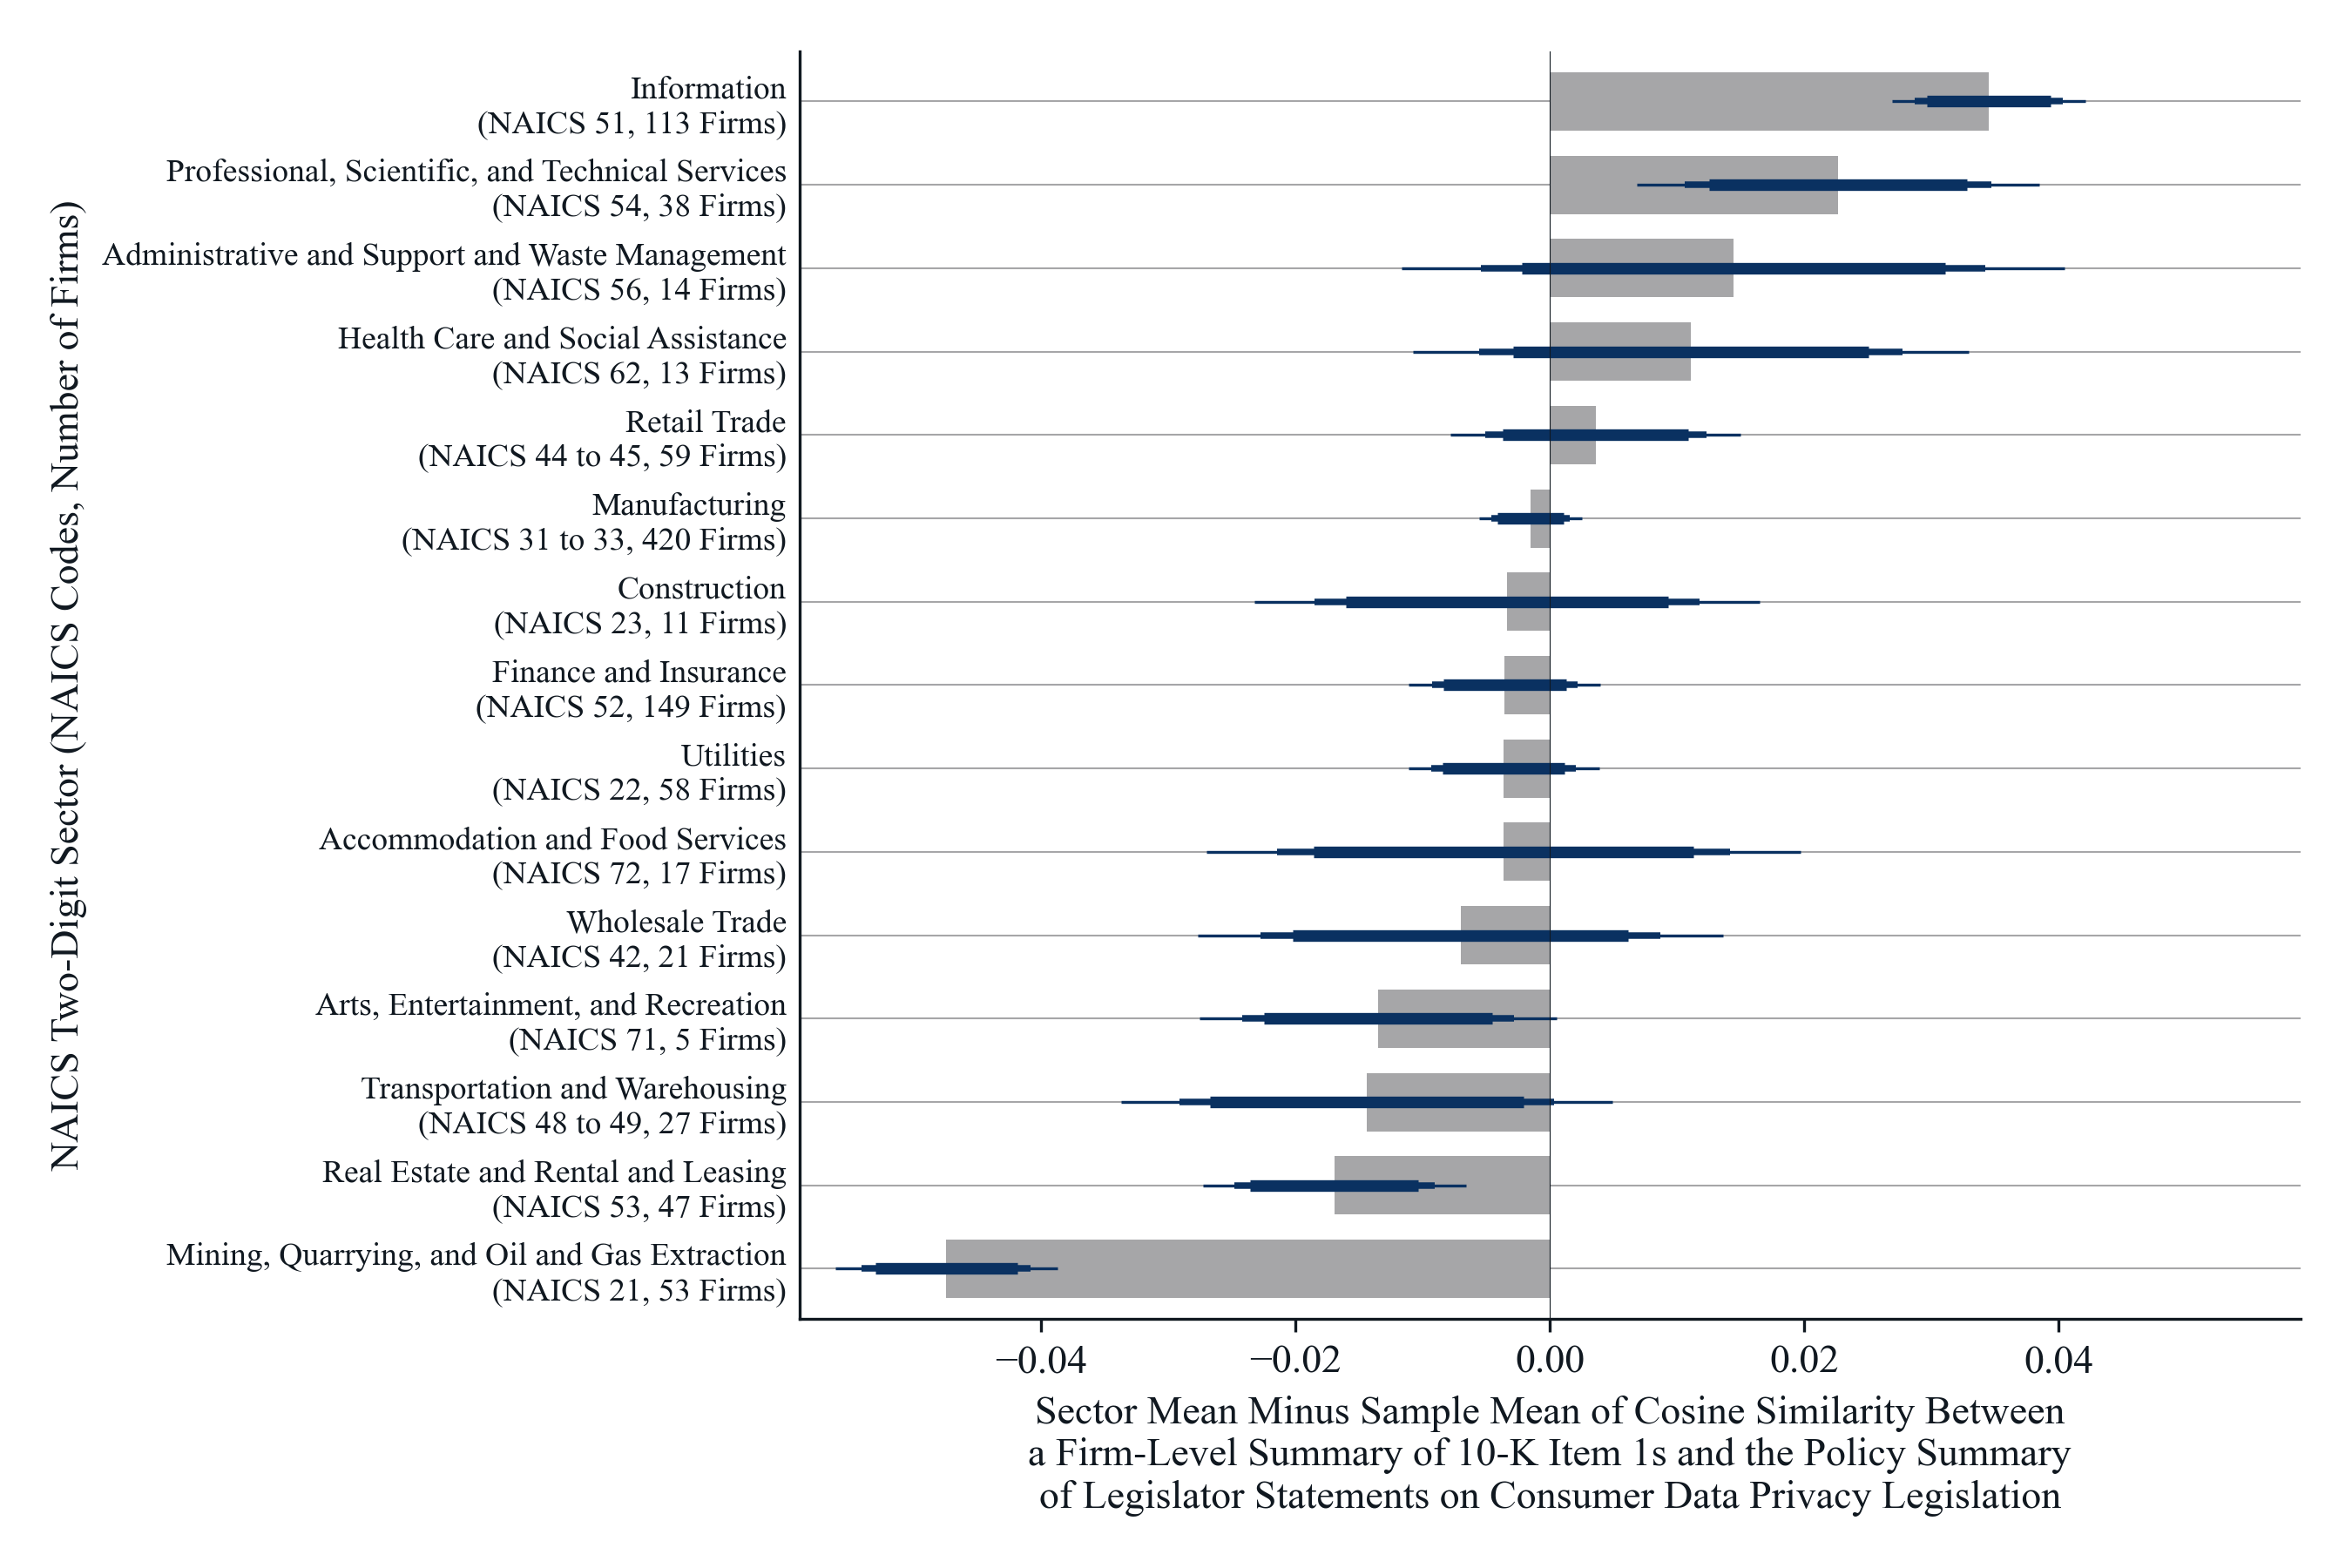

*Notes*: Each bar is the sector mean minus the sample mean of the firm score, the mean over all 1,058 firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 0.512: zero is the sample mean, a bar to the right is a sector above it and a bar to the left a sector below it, and sectors are ordered from the highest mean at the top to the lowest at the bottom. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. The three nested lines span the 90, 95, and 99 percent confidence intervals of the sector mean, the thickest line the 90 percent and the thinnest the 99 percent, 1.645, 1.96, and 2.576 standard errors on each side, where the standard error is the standard deviation of the firm scores within the sector divided by the square root of the number of firms; an interval that does not cross zero marks a sector whose mean differs from the sample mean at that confidence level. The sector is the firm's Compustat NAICS code cut to two digits, with codes 31 to 33 merged into manufacturing, 44 to 45 into retail trade, and 48 to 49 into transportation and warehousing; each tick label gives the codes and the number of firms. Sectors with fewer than 5 firms are left out: Unclassified (NAICS 99, 4 firms); Other Services (NAICS 81, 3 firms); Agriculture, Forestry, Fishing and Hunting (NAICS 11, 3 firms); Educational Services (NAICS 61, 3 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 2. Sector Median Minus Sample Median of Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation, by NAICS Two-Digit Sector**

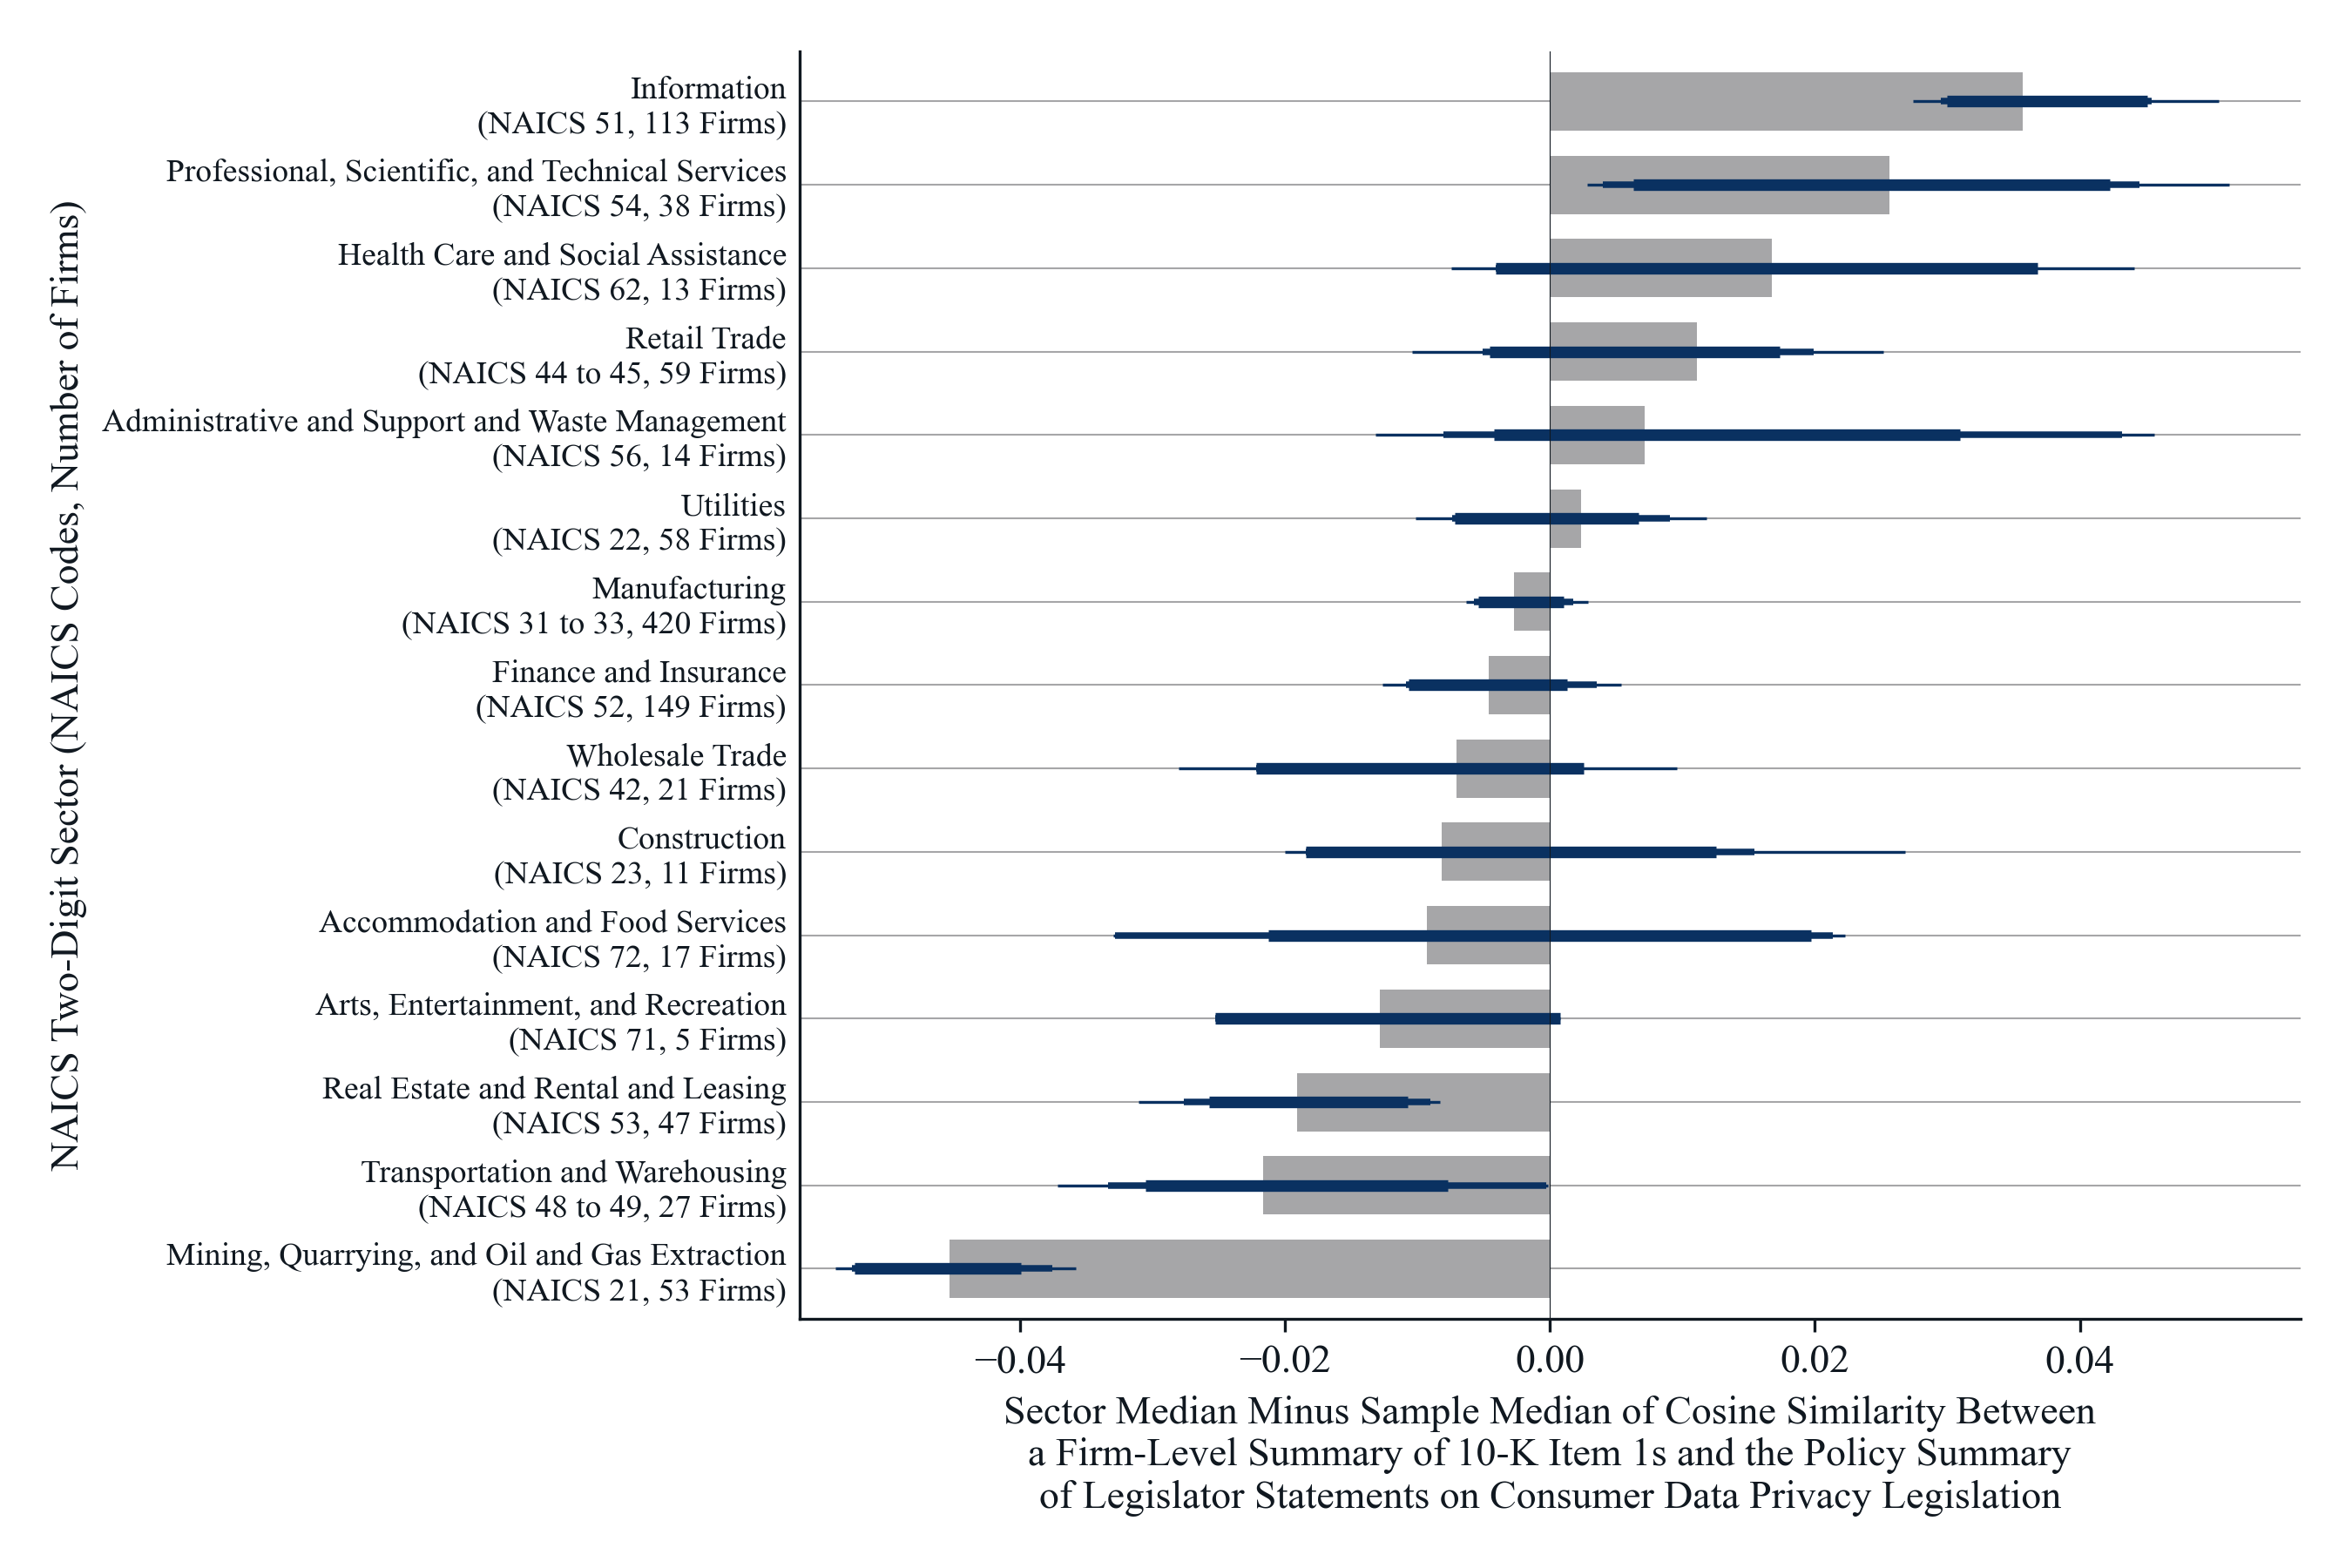

*Notes*: Each bar is the sector median minus the sample median of the firm score, the median over all 1,058 firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 0.511: zero is the sample median, a bar to the right is a sector above it and a bar to the left a sector below it, and sectors are ordered from the highest median at the top to the lowest at the bottom. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. The three nested lines span the 90, 95, and 99 percent percentile bootstrap intervals of the sector median, the thickest line the 90 percent and the thinnest the 99 percent: the sector's firms are resampled with replacement 5,000 times, the median is taken each time, and each interval is the central 90, 95, or 99 percent of those medians, so an interval can be asymmetric around the bar end; an interval that does not cross zero marks a sector whose median differs from the sample median at that confidence level. The sector is the firm's Compustat NAICS code cut to two digits, with codes 31 to 33 merged into manufacturing, 44 to 45 into retail trade, and 48 to 49 into transportation and warehousing; each tick label gives the codes and the number of firms. Sectors with fewer than 5 firms are left out: Unclassified (NAICS 99, 4 firms); Agriculture, Forestry, Fishing and Hunting (NAICS 11, 3 firms); Other Services (NAICS 81, 3 firms); Educational Services (NAICS 61, 3 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 3. Subsector Mean Minus Sample Mean of Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation, by NAICS Three-Digit Subsector**

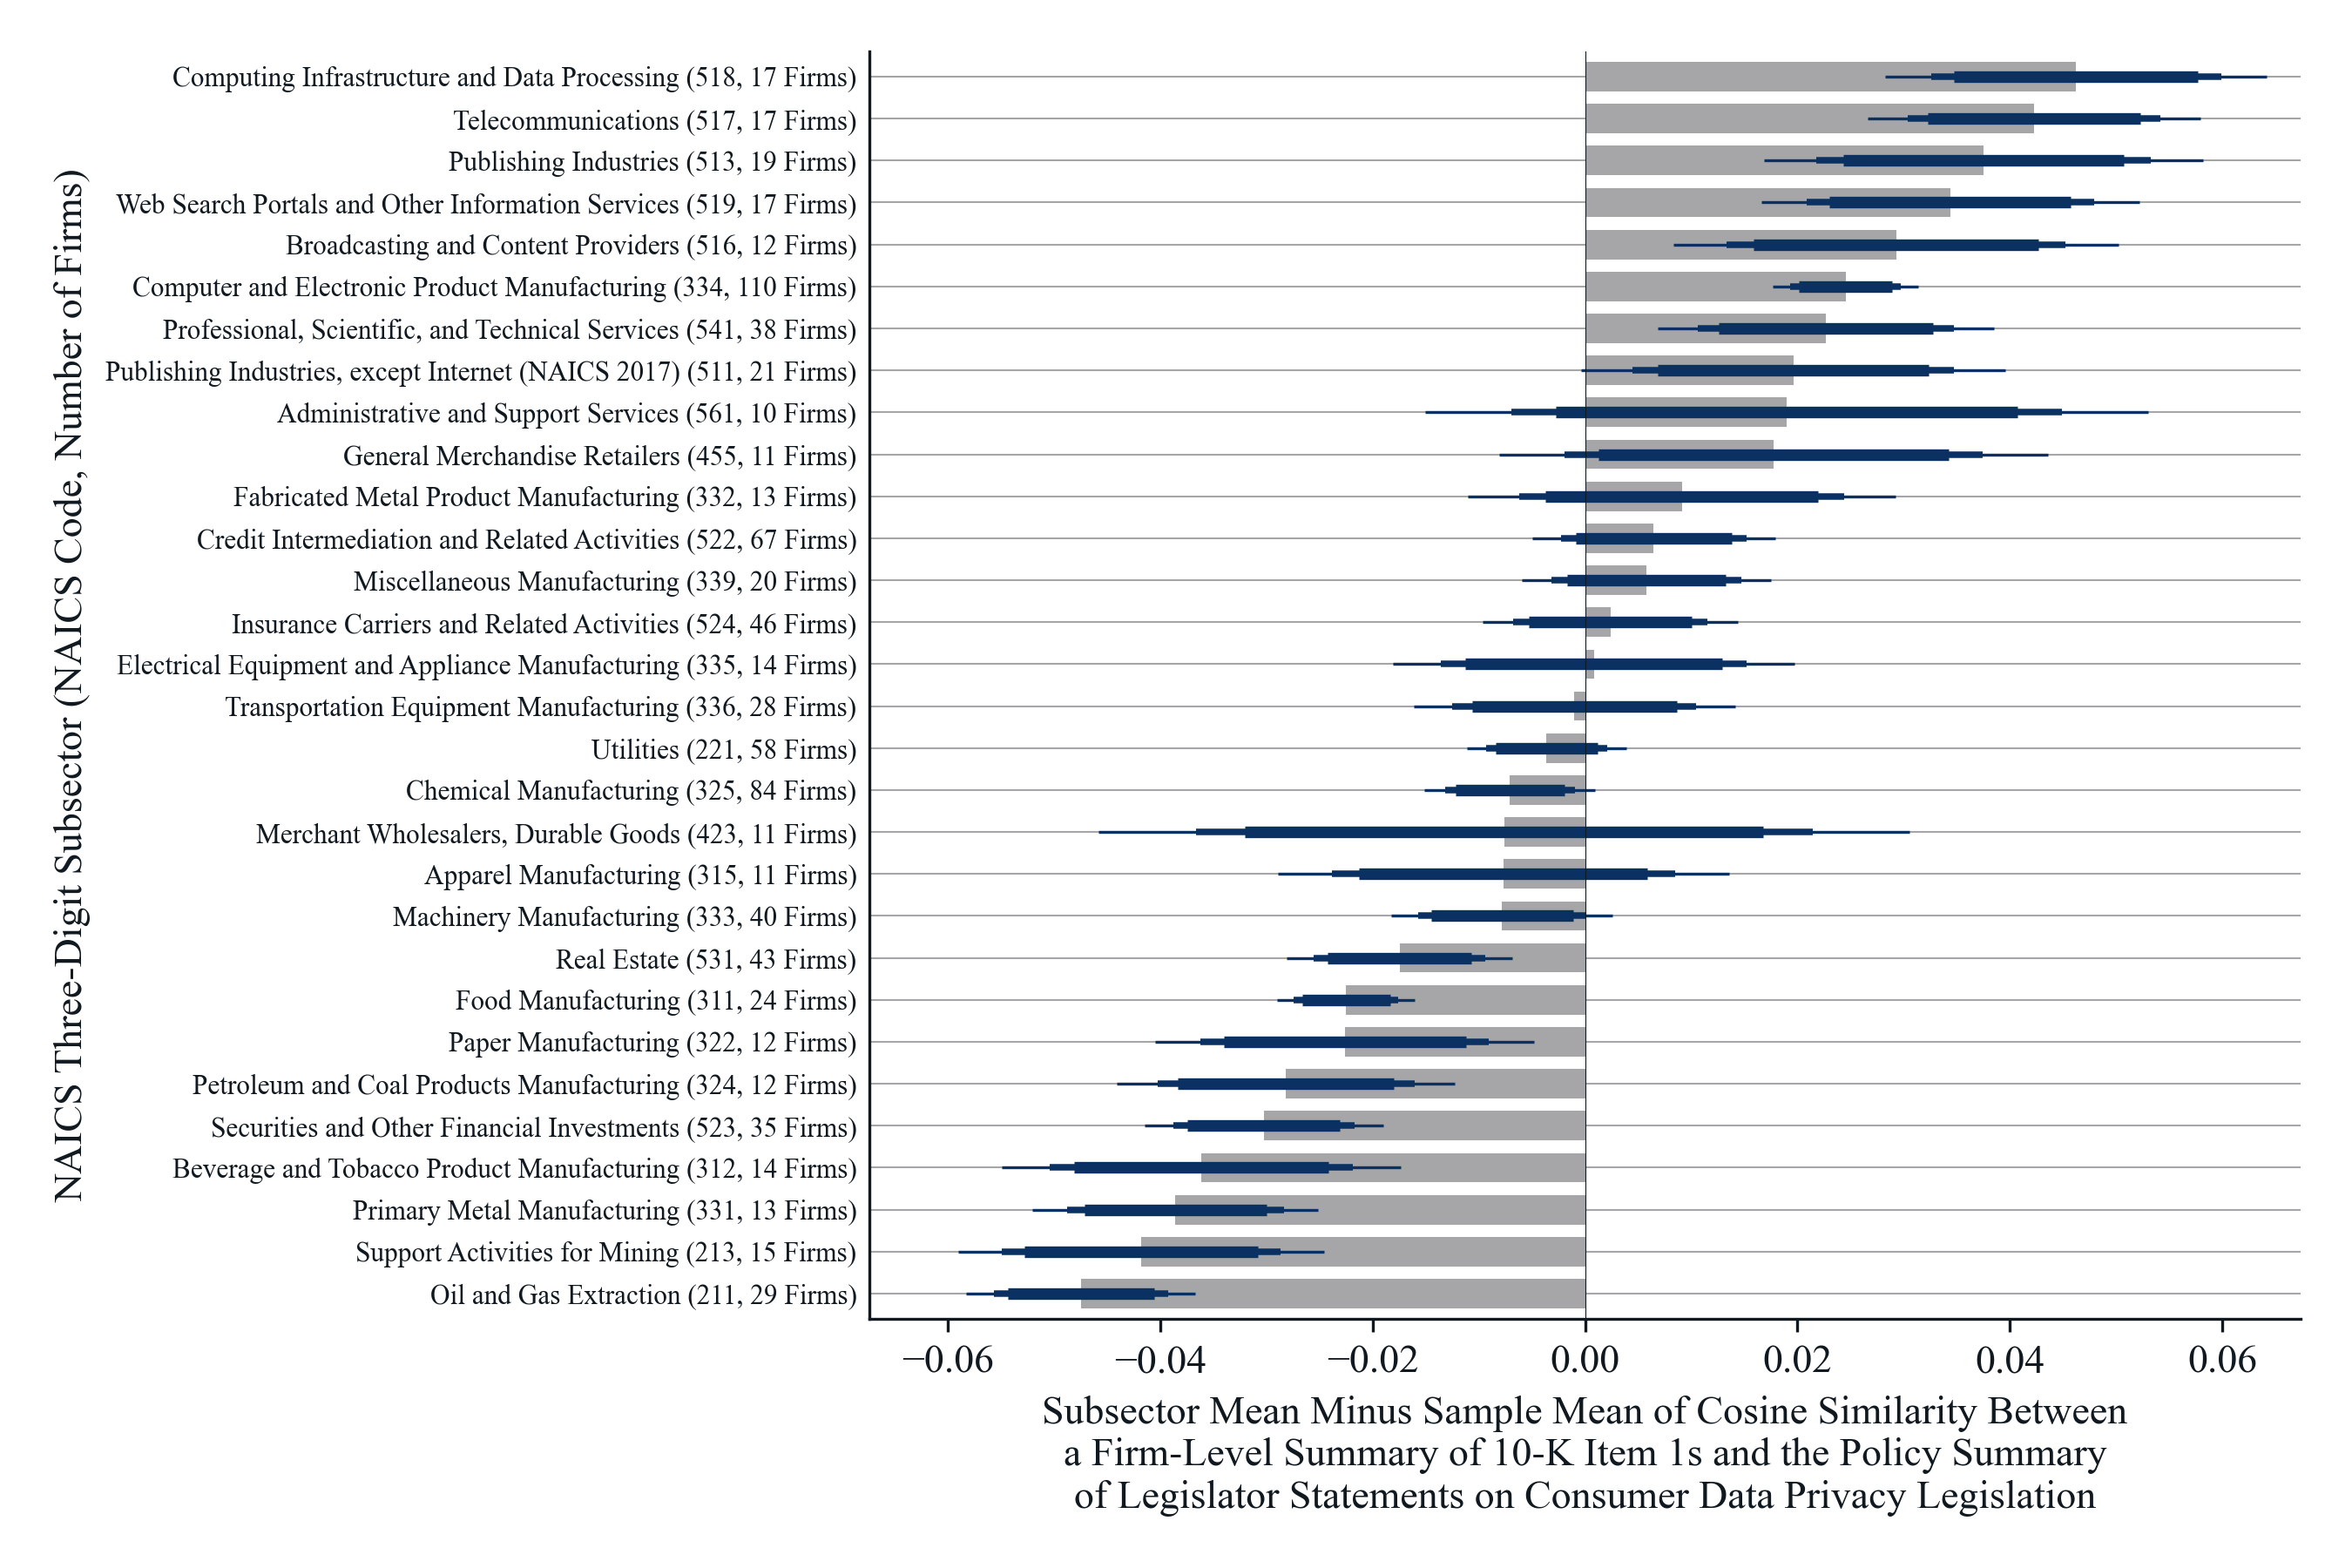

*Notes*: Each bar is the subsector mean minus the sample mean of the firm score, the mean over all 1,058 firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 0.512: zero is the sample mean, a bar to the right is a subsector above it and a bar to the left a subsector below it, and subsectors are ordered from the highest mean at the top to the lowest at the bottom. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. The three nested lines span the 90, 95, and 99 percent confidence intervals of the subsector mean, the thickest line the 90 percent and the thinnest the 99 percent, 1.645, 1.96, and 2.576 standard errors on each side, where the standard error is the standard deviation of the firm scores within the subsector divided by the square root of the number of firms; an interval that does not cross zero marks a subsector whose mean differs from the sample mean at that confidence level. The subsector is the firm's Compustat NAICS code cut to three digits, named by NAICS 2022 where the code exists in that vintage and by the older vintage otherwise; each tick label gives the code and the number of firms. Subsectors with fewer than 10 firms are left out: Couriers and Messengers (NAICS 492, 2 firms); Transit and Ground Passenger Transportation (NAICS 485, 1 firms); Broadcasting, except Internet (NAICS 2017) (NAICS 515, 7 firms); Furniture, Electronics, and Appliance Retailers (NAICS 449, 4 firms); Unclassified (NAICS 999, 4 firms); Electronics and Appliance Stores (NAICS 2017) (NAICS 443, 2 firms); Building Material and Garden Supplies Dealers (NAICS 444, 2 firms); Air Transportation (NAICS 481, 5 firms); Crop Production (NAICS 111, 2 firms); Wholesale Trade, Nondurable Goods (NAICS 1997) (NAICS 422, 1 firms); Motion Picture and Sound Recording Industries (NAICS 512, 3 firms); Specialty Trade Contractors (NAICS 238, 3 firms); Clothing and Clothing Accessories Stores (NAICS 2017) (NAICS 448, 1 firms); Miscellaneous Store Retailers (NAICS 2017) (NAICS 453, 1 firms); Ambulatory Health Care Services (NAICS 621, 6 firms); Hospitals (NAICS 622, 5 firms); Nursing and Residential Care Facilities (NAICS 623, 2 firms); Sporting Goods, Hobby, and Book Stores (NAICS 2017) (NAICS 451, 1 firms); Food Services and Drinking Places (NAICS 722, 8 firms); Motor Vehicle and Parts Dealers (NAICS 441, 7 firms); Food and Beverage Retailers (NAICS 445, 6 firms); Waste Management and Remediation Services (NAICS 562, 4 firms); Personal and Laundry Services (NAICS 812, 3 firms); Rental and Leasing Services (NAICS 532, 3 firms); Wholesale Trade Agents and Brokers (NAICS 425, 1 firms); Furniture and Related Product Manufacturing (NAICS 337, 2 firms); Health and Personal Care Stores (NAICS 2017) (NAICS 446, 5 firms); Construction of Buildings (NAICS 236, 6 firms); Merchant Wholesalers, Nondurable Goods (NAICS 424, 7 firms); Plastics and Rubber Products Manufacturing (NAICS 326, 9 firms); Clothing, Shoe, and Jewelry Retailers (NAICS 458, 8 firms); Accommodation (NAICS 721, 9 firms); Amusement, Gambling, and Recreation Industries (NAICS 713, 3 firms); Educational Services (NAICS 611, 3 firms); Performing Arts, Spectator Sports, and Related Industries (NAICS 711, 2 firms); Health and Personal Care Retailers (NAICS 456, 4 firms); Funds, Trusts, and Other Financial Vehicles (NAICS 525, 1 firms); General Merchandise Stores (NAICS 2017) (NAICS 452, 5 firms); Leather and Allied Product Manufacturing (NAICS 316, 4 firms); Printing and Related Support Activities (NAICS 323, 2 firms); Heavy and Civil Engineering Construction (NAICS 237, 2 firms); Textile Mills (NAICS 313, 1 firms); Truck Transportation (NAICS 484, 3 firms); Rail Transportation (NAICS 482, 5 firms); Wood Product Manufacturing (NAICS 321, 3 firms); Textile Product Mills (NAICS 314, 1 firms); Wholesale Trade, No Three-Digit Code (NAICS 42, 1 firms); Nonmetallic Mineral Product Manufacturing (NAICS 327, 3 firms); Sporting Goods, Hobby, Book, and Miscellaneous Retailers (NAICS 459, 2 firms); Support Activities for Transportation (NAICS 488, 1 firms); Pipeline Transportation (NAICS 486, 7 firms); Forestry and Logging (NAICS 113, 1 firms); Water Transportation (NAICS 483, 3 firms); Lessors of Nonfinancial Intangible Assets (NAICS 533, 1 firms); Mining, except Oil and Gas (NAICS 212, 9 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 4. Subsector Median Minus Sample Median of Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation, by NAICS Three-Digit Subsector**

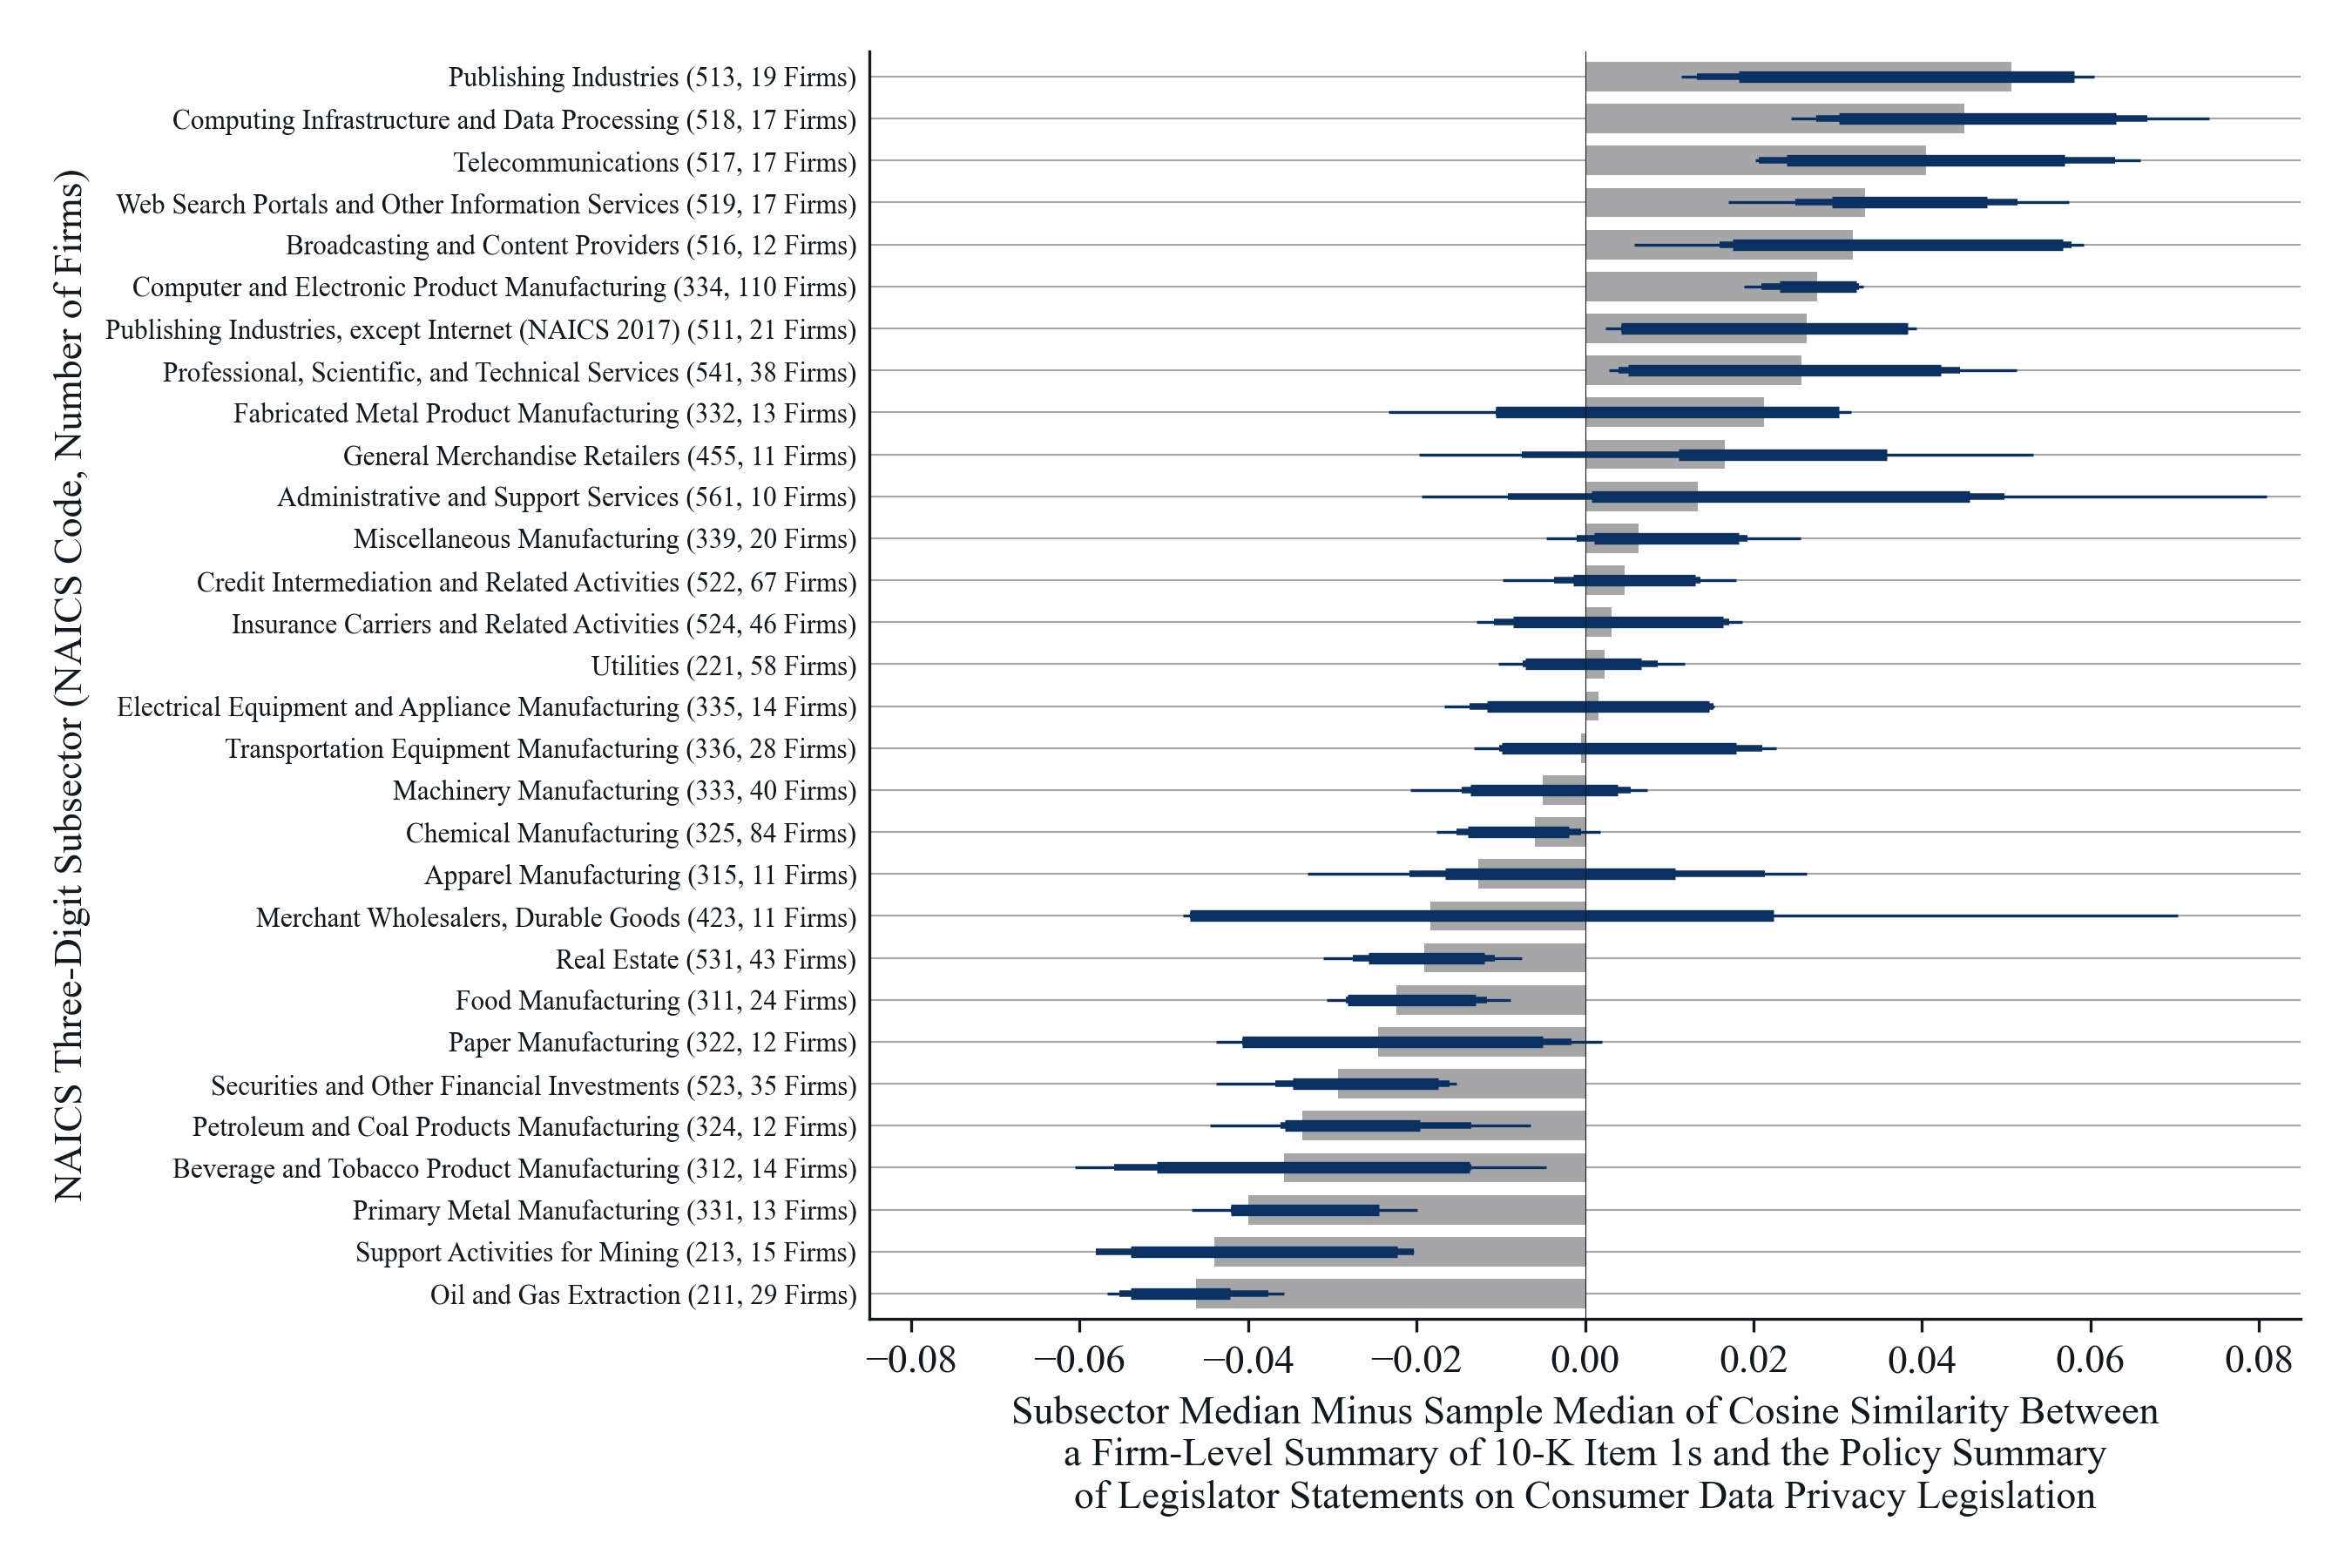

*Notes*: Each bar is the subsector median minus the sample median of the firm score, the median over all 1,058 firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 0.511: zero is the sample median, a bar to the right is a subsector above it and a bar to the left a subsector below it, and subsectors are ordered from the highest median at the top to the lowest at the bottom. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. The three nested lines span the 90, 95, and 99 percent percentile bootstrap intervals of the subsector median, the thickest line the 90 percent and the thinnest the 99 percent: the subsector's firms are resampled with replacement 5,000 times, the median is taken each time, and each interval is the central 90, 95, or 99 percent of those medians, so an interval can be asymmetric around the bar end; an interval that does not cross zero marks a subsector whose median differs from the sample median at that confidence level. The subsector is the firm's Compustat NAICS code cut to three digits, named by NAICS 2022 where the code exists in that vintage and by the older vintage otherwise; each tick label gives the code and the number of firms. Subsectors with fewer than 10 firms are left out: Couriers and Messengers (NAICS 492, 2 firms); Transit and Ground Passenger Transportation (NAICS 485, 1 firms); Broadcasting, except Internet (NAICS 2017) (NAICS 515, 7 firms); Unclassified (NAICS 999, 4 firms); Furniture, Electronics, and Appliance Retailers (NAICS 449, 4 firms); Food and Beverage Retailers (NAICS 445, 6 firms); Electronics and Appliance Stores (NAICS 2017) (NAICS 443, 2 firms); Air Transportation (NAICS 481, 5 firms); Motor Vehicle and Parts Dealers (NAICS 441, 7 firms); Building Material and Garden Supplies Dealers (NAICS 444, 2 firms); Crop Production (NAICS 111, 2 firms); Hospitals (NAICS 622, 5 firms); Wholesale Trade, Nondurable Goods (NAICS 1997) (NAICS 422, 1 firms); Clothing and Clothing Accessories Stores (NAICS 2017) (NAICS 448, 1 firms); Specialty Trade Contractors (NAICS 238, 3 firms); Miscellaneous Store Retailers (NAICS 2017) (NAICS 453, 1 firms); Food Services and Drinking Places (NAICS 722, 8 firms); Ambulatory Health Care Services (NAICS 621, 6 firms); Nursing and Residential Care Facilities (NAICS 623, 2 firms); Sporting Goods, Hobby, and Book Stores (NAICS 2017) (NAICS 451, 1 firms); Motion Picture and Sound Recording Industries (NAICS 512, 3 firms); Personal and Laundry Services (NAICS 812, 3 firms); Wholesale Trade Agents and Brokers (NAICS 425, 1 firms); Furniture and Related Product Manufacturing (NAICS 337, 2 firms); Clothing, Shoe, and Jewelry Retailers (NAICS 458, 8 firms); Waste Management and Remediation Services (NAICS 562, 4 firms); Health and Personal Care Stores (NAICS 2017) (NAICS 446, 5 firms); Construction of Buildings (NAICS 236, 6 firms); Merchant Wholesalers, Nondurable Goods (NAICS 424, 7 firms); Rental and Leasing Services (NAICS 532, 3 firms); Plastics and Rubber Products Manufacturing (NAICS 326, 9 firms); Performing Arts, Spectator Sports, and Related Industries (NAICS 711, 2 firms); Amusement, Gambling, and Recreation Industries (NAICS 713, 3 firms); Funds, Trusts, and Other Financial Vehicles (NAICS 525, 1 firms); Leather and Allied Product Manufacturing (NAICS 316, 4 firms); Educational Services (NAICS 611, 3 firms); Health and Personal Care Retailers (NAICS 456, 4 firms); Printing and Related Support Activities (NAICS 323, 2 firms); Heavy and Civil Engineering Construction (NAICS 237, 2 firms); Textile Mills (NAICS 313, 1 firms); Accommodation (NAICS 721, 9 firms); Rail Transportation (NAICS 482, 5 firms); General Merchandise Stores (NAICS 2017) (NAICS 452, 5 firms); Textile Product Mills (NAICS 314, 1 firms); Wholesale Trade, No Three-Digit Code (NAICS 42, 1 firms); Pipeline Transportation (NAICS 486, 7 firms); Truck Transportation (NAICS 484, 3 firms); Sporting Goods, Hobby, Book, and Miscellaneous Retailers (NAICS 459, 2 firms); Support Activities for Transportation (NAICS 488, 1 firms); Wood Product Manufacturing (NAICS 321, 3 firms); Nonmetallic Mineral Product Manufacturing (NAICS 327, 3 firms); Forestry and Logging (NAICS 113, 1 firms); Water Transportation (NAICS 483, 3 firms); Mining, except Oil and Gas (NAICS 212, 9 firms); Lessors of Nonfinancial Intangible Assets (NAICS 533, 1 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [7]:
for figure_number, figure_name, title, notes in figure_records:
    display(Markdown(f"**Figure {figure_number}. {title}**"))
    display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
    display(Markdown(f"*Notes*: {notes}"))
    display(Markdown(f"*Source*: {SOURCE}."))
